In [23]:
import tensorflow as tf
import numpy as np
import pandas as pd
from pylab import rcParams
import matplotlib.pyplot as plt
import warnings
from mlxtend.plotting import plot_decision_regions
from matplotlib.colors import ListedColormap
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles
import seaborn as sns

In [24]:
X, y = make_circles(n_samples=100, noise = 0.1, random_state=1)

<Axes: >

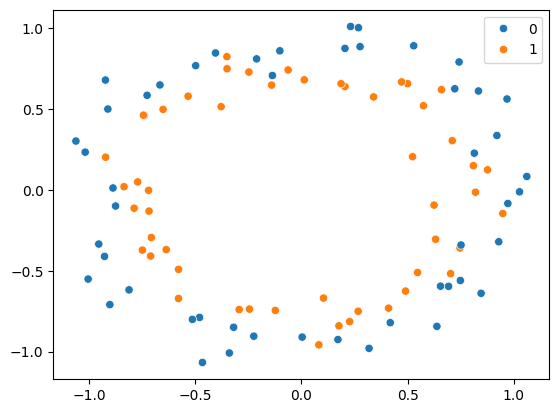

In [25]:

sns.scatterplot(x = X[:,0],y =X[:,1],hue=y)

In [17]:
x_train, x_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state=2)

model = Sequential()

model.add(Dense(256, input_dim=2, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

history = model.fit(x_train, y_train, validation_data = (x_test, y_test), epochs = 3500, verbose=0)

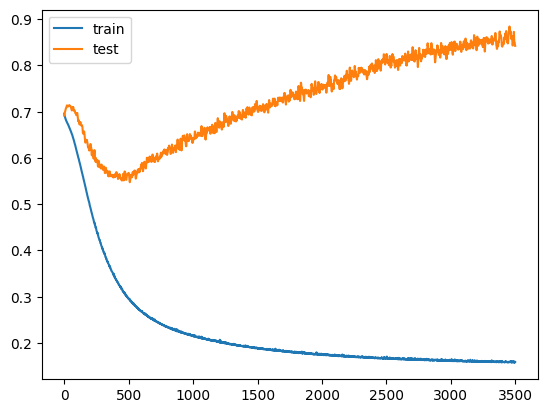

In [18]:
plt.plot(history.history['loss'],label='train')
plt.plot(history.history['val_loss'], label = 'test')
plt.legend()
plt.show()



9600/9600 ━━━━━━━━━━━━━━━━━━━━ 15s 2ms/step


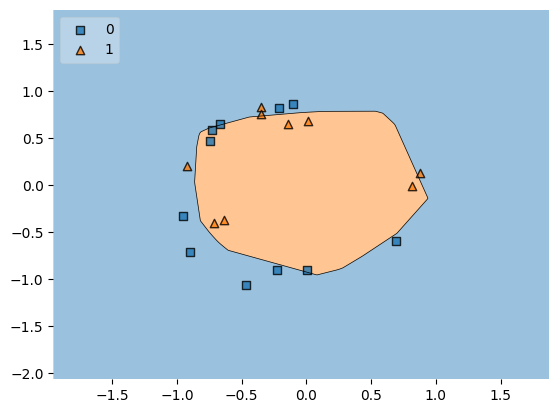

In [19]:
plot_decision_regions(x_test, y_test.ravel(), clf= model, legend=2)
plt.show()

**Early stopping **

In [28]:
model = Sequential()

model.add(Dense(256, input_dim=2, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

callback = EarlyStopping(
    monitor="val_loss",
    min_delta=0.00001,
    patience=20,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False
)

history = model.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=3500, callbacks=callback)


Epoch 1/3500


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 336ms/step - accuracy: 0.4875 - loss: 0.6929 - val_accuracy: 0.4000 - val_loss: 0.7069
Epoch 2/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.5625 - loss: 0.6903 - val_accuracy: 0.4000 - val_loss: 0.7091
Epoch 3/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.5500 - loss: 0.6890 - val_accuracy: 0.4000 - val_loss: 0.7115
Epoch 4/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5625 - loss: 0.6877 - val_accuracy: 0.4000 - val_loss: 0.7143
Epoch 5/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5500 - loss: 0.6867 - val_accuracy: 0.4000 - val_loss: 0.7161
Epoch 6/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5750 - loss: 0.6858 - val_accuracy: 0.4000 - val_loss: 0.7163
Epoch 7/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.5500 - loss: 0.6845 - val_accuracy: 0.4000 - val_loss: 0.7168
Epoch 8/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5625 - loss: 0.6838 - val_accuracy: 0.4000 - val_loss: 0.7

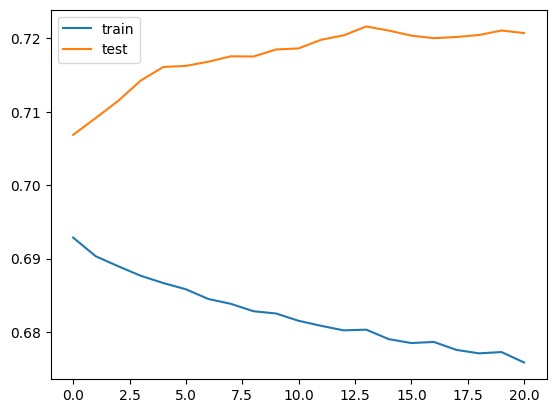

In [29]:
plt.plot(history.history['loss'],label = 'train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step


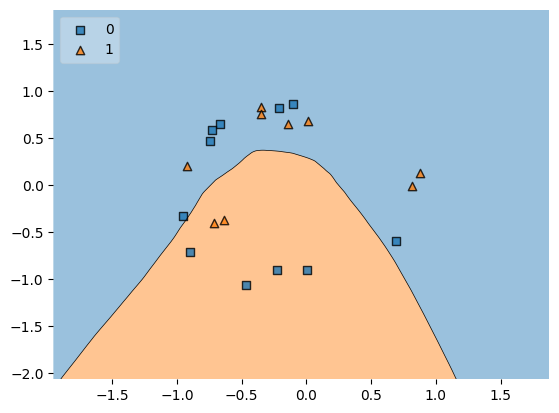

In [31]:
plot_decision_regions(x_test, y_test.ravel(), clf = model, legend=2)
plt.show()